In [1]:
import pandas as pd

DATA_URL = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
DATA_FILE = "insurance.csv"

# Download the full dataset and save it in the Colab session
insurance = pd.read_csv(DATA_URL)
insurance.to_csv(DATA_FILE, index=False)

print(f"Loaded dataset: {insurance.shape[0]:,} rows, {insurance.shape[1]} columns")
print(f"Saved as '{DATA_FILE}'")
insurance.head()

Loaded dataset: 1,338 rows, 7 columns
Saved as 'insurance.csv'


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [2]:
print("Attributes:")
print(list(insurance.columns))

print("\nNumber of instances:", len(insurance))

print("\nData types:")
print(insurance.dtypes)

print("\nMissing values in each attribute:")
missing = insurance.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "No missing values")

print("\nDuplicate rows:", insurance.duplicated().sum())

print("\nSummary of the output (charges):")
print(insurance["charges"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(2))

print("\nCategories in each text column:")
for col in ["sex", "smoker", "region"]:
    print(f"  {col}: {insurance[col].value_counts().to_dict()}")

Attributes:
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

Number of instances: 1338

Data types:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

Missing values in each attribute:
No missing values

Duplicate rows: 1

Summary of the output (charges):
count     1338.00
mean     13270.42
std      12110.01
min       1121.87
25%       4740.29
50%       9382.03
75%      16639.91
95%      41181.83
99%      48537.48
max      63770.43
Name: charges, dtype: float64

Categories in each text column:
  sex: {'male': 676, 'female': 662}
  smoker: {'no': 1064, 'yes': 274}
  region: {'southeast': 364, 'southwest': 325, 'northwest': 325, 'northeast': 324}


In [3]:
# 1. Remove the duplicate row
rows_before = len(insurance)
insurance = insurance.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows removed: {rows_before - len(insurance)}")
print(f"Instances remaining   : {len(insurance):,}")

# 2. Feature extraction: separate input features (X) from output (y)
numeric_features = ["age", "bmi", "children"]
categorical_features = ["sex", "smoker", "region"]
target = "charges"

X = insurance[numeric_features + categorical_features]
y = insurance[target]

print(f"\nInput features (X): {X.shape[1]} columns -> {list(X.columns)}")
print(f"Output (y)        : {target}")
print(f"Number of records : {len(X):,}")

X.head()

Duplicate rows removed: 1
Instances remaining   : 1,337

Input features (X): 6 columns -> ['age', 'bmi', 'children', 'sex', 'smoker', 'region']
Output (y)        : charges
Number of records : 1,337


,age,bmi,children,sex,smoker,region
0,19,27.900,0,female,yes,southwest
1,18,33.770,1,male,no,southeast
2,28,33.000,3,male,no,southeast
3,33,22.705,0,male,no,northwest
4,32,28.880,0,male,no,northwest


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

print("Pre-processing pipeline created.")

# Quick check only (NOT used for training): see what the pipeline produces
check = preprocessor.fit_transform(X)
feature_names = preprocessor.get_feature_names_out()
print(f"\nTransformed shape: {check.shape}")
print("Feature names after encoding:")
for name in feature_names:
    print("  ", name)

Pre-processing pipeline created.

Transformed shape: (1337, 11)
Feature names after encoding:
   num__age
   num__bmi
   num__children
   cat__sex_female
   cat__sex_male
   cat__smoker_no
   cat__smoker_yes
   cat__region_northeast
   cat__region_northwest
   cat__region_southeast
   cat__region_southwest


In [5]:
!pip install catboost -q

import xgboost, lightgbm, catboost, sklearn
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor

algorithms = {
    "XGBoost": XGBRegressor(random_state=42, n_jobs=-1),
    "LightGBM": LGBMRegressor(random_state=42, n_jobs=-1, verbose=-1),
    "CatBoost": CatBoostRegressor(random_state=42, verbose=0),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
}

print("Library versions:")
print(f"  XGBoost      : {xgboost.__version__}")
print(f"  LightGBM     : {lightgbm.__version__}")
print(f"  CatBoost     : {catboost.__version__}")
print(f"  scikit-learn : {sklearn.__version__}")

print("\nAlgorithms to compare:")
for number, name in enumerate(algorithms, start=1):
    print(f"  {number}. {name}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.9 MB/s eta 0:00:00
Library versions:
  XGBoost      : 3.4.1
  LightGBM     : 4.6.0
  CatBoost     : 1.2.10
  scikit-learn : 1.6.1

Algorithms to compare:
  1. XGBoost
  2. LightGBM
  3. CatBoost
  4. HistGradientBoosting
  5. Random Forest


In [7]:
print(f"{K}-Fold Cross Validation created (shuffle=True, random_state=42)\n")
print(f"{'Fold':<6}{'Train records':>15}{'Test records':>15}")
print("-" * 36)
for fold_number, (train_idx, test_idx) in enumerate(kfold.split(X), start=1):
    print(f"{fold_number:<6}{len(train_idx):>15,}{len(test_idx):>15,}")

10-Fold Cross Validation created (shuffle=True, random_state=42)

Fold    Train records   Test records
------------------------------------
1               1,203            134
2               1,203            134
3               1,203            134
4               1,203            134
5               1,203            134
6               1,203            134
7               1,203            134
8               1,204            133
9               1,204            133
10              1,204            133


In [8]:
import time
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import mean_squared_error
from tqdm import tqdm

fold_rmse = {name: [] for name in algorithms}   # RMSE of each algorithm on each fold
run_time = {name: 0.0 for name in algorithms}   # total training time per algorithm

for name, model in algorithms.items():
    start = time.time()
    for train_idx, test_idx in tqdm(kfold.split(X), total=K, desc=f"{name:<22}"):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        # Fresh pipeline for every fold: pre-processing is fitted on training folds only
        pipe = Pipeline([
            ("preprocess", clone(preprocessor)),
            ("model", clone(model)),
        ])
        pipe.fit(X_train, y_train)
        predictions = pipe.predict(X_test)

        rmse = np.sqrt(mean_squared_error(y_test, predictions))
        fold_rmse[name].append(rmse)
    run_time[name] = time.time() - start

print("\nDone. Mean RMSE over 10 folds:")
for name in algorithms:
    print(f"  {name:<22} ${np.mean(fold_rmse[name]):>10,.2f}   (time: {run_time[name]:.1f}s)")

LightGBM              :   0%|          | 0/10 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
LightGBM              :  10%|█         | 1/10 [00:00<00:02,  3.49it/s]/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
LightGBM              :  20%|██        | 2/10 [00:00<00:02,  3.48it/s]/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
LightGBM              :  30%|███       | 3/10 [00:01<00:02,  2.50it/s]/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with fea


Done. Mean RMSE over 10 folds:
  XGBoost                $  5,160.96   (time: 5.7s)
  LightGBM               $  4,754.27   (time: 3.6s)
  CatBoost               $  4,731.81   (time: 10.0s)
  HistGradientBoosting   $  4,765.95   (time: 2.5s)
  Random Forest          $  4,824.22   (time: 4.8s)


RMSE of each algorithm on each fold ($):


,XGBoost,LightGBM,CatBoost,HistGradientBoosting,Random Forest
Fold 1,"5,128.96","4,495.87","4,694.63","4,561.90","4,885.41"
Fold 2,"4,779.74","4,624.76","4,484.02","4,535.40","4,513.71"
Fold 3,"5,776.38","5,470.52","5,574.02","5,463.36","5,339.42"
Fold 4,"5,161.74","4,787.40","4,768.39","4,820.12","4,898.06"
Fold 5,"5,096.97","4,779.81","4,665.40","4,782.23","4,852.78"
Fold 6,"6,171.91","5,357.65","5,300.28","5,361.81","5,505.41"
Fold 7,"4,515.86","3,979.96","3,964.94","4,070.45","4,145.70"
Fold 8,"5,078.47","4,652.30","4,666.80","4,747.42","4,761.66"
Fold 9,"4,905.90","4,602.01","4,621.62","4,597.89","4,794.66"
Fold 10,"4,993.64","4,792.47","4,577.96","4,718.90","4,545.41"



Summary (sorted by mean RMSE, lower is better):


,Rank,Mean RMSE ($),Std Dev ($),Best Fold ($),Worst Fold ($),Time (s)
CatBoost,1,"4,731.81",438.32,"3,964.94","5,574.02",9.95
LightGBM,2,"4,754.27",421.24,"3,979.96","5,470.52",3.62
HistGradientBoosting,3,"4,765.95",401.93,"4,070.45","5,463.36",2.47
Random Forest,4,"4,824.22",391.41,"4,145.70","5,505.41",4.78
XGBoost,5,"5,160.96",479.26,"4,515.86","6,171.91",5.72


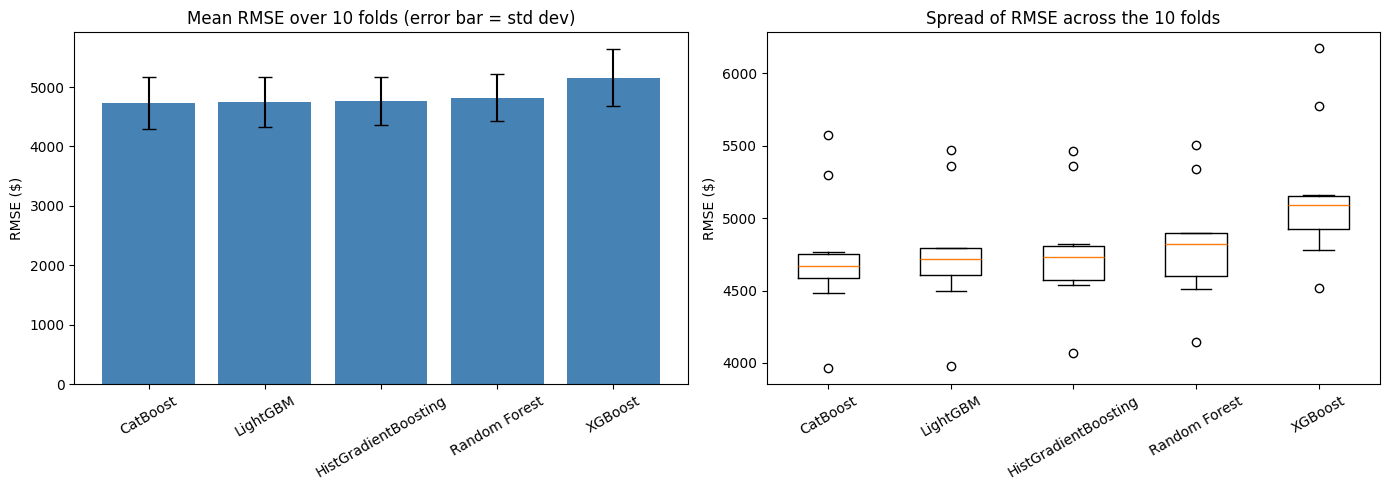


Best algorithm: CatBoost (mean RMSE = $4,731.81)


In [9]:
import warnings
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# 9.1 RMSE of each algorithm on each fold
fold_table = pd.DataFrame(fold_rmse, index=[f"Fold {i}" for i in range(1, K + 1)])
print("RMSE of each algorithm on each fold ($):")
display(fold_table)

# 9.2 Summary comparison table
summary = pd.DataFrame({
    "Mean RMSE ($)": fold_table.mean(),
    "Std Dev ($)": fold_table.std(),
    "Best Fold ($)": fold_table.min(),
    "Worst Fold ($)": fold_table.max(),
    "Time (s)": pd.Series(run_time),
}).sort_values("Mean RMSE ($)")
summary.insert(0, "Rank", range(1, len(summary) + 1))
print("\nSummary (sorted by mean RMSE, lower is better):")
display(summary)

# 9.3 Visual comparison
order = summary.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(order, summary["Mean RMSE ($)"], yerr=summary["Std Dev ($)"],
            capsize=5, color="steelblue")
axes[0].set_title("Mean RMSE over 10 folds (error bar = std dev)")
axes[0].set_ylabel("RMSE ($)")
axes[0].tick_params(axis="x", rotation=30)

axes[1].boxplot([fold_table[n] for n in order], labels=order)
axes[1].set_title("Spread of RMSE across the 10 folds")
axes[1].set_ylabel("RMSE ($)")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

print(f"\nBest algorithm: {order[0]} (mean RMSE = ${summary.iloc[0]['Mean RMSE ($)']:,.2f})")

In [10]:
import pickle
from catboost import CatBoostRegressor

best_name = summary.index[0]
print(f"Best algorithm selected: {best_name}")

# Train a fresh pipeline (pre-processing + best model) on ALL the data
final_model = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", clone(algorithms[best_name])),
])
final_model.fit(X, y)
print("Final model trained on all", len(X), "records.")

# Save the trained pipeline to a file
MODEL_FILE = "insurance_model.pkl"
with open(MODEL_FILE, "wb") as f:
    pickle.dump(final_model, f)
print(f"Model saved as '{MODEL_FILE}'")

# Quick sanity check: reload the file and predict for one sample person
with open(MODEL_FILE, "rb") as f:
    loaded_model = pickle.load(f)

sample = pd.DataFrame([{
    "age": 35, "bmi": 28.0, "children": 2,
    "sex": "male", "smoker": "no", "region": "northeast",
}])
print(f"\nSample prediction (35-year-old non-smoker): ${loaded_model.predict(sample)[0]:,.2f}")

Best algorithm selected: CatBoost
Final model trained on all 1337 records.
Model saved as 'insurance_model.pkl'

Sample prediction (35-year-old non-smoker): $7,443.93


In [11]:
import pickle
import pandas as pd

# 11.1 Take input from the user
def ask_number(prompt, low, high, as_int=False):
    while True:
        try:
            value = float(input(prompt))
            if low <= value <= high:
                return int(value) if as_int else value
            print(f"  Please enter a value between {low} and {high}.")
        except ValueError:
            print("  Please enter a valid number.")

def ask_choice(prompt, choices):
    while True:
        value = input(prompt).strip().lower()
        if value in choices:
            return value
        print(f"  Please enter one of: {', '.join(choices)}")

print("Enter the person's details:\n")
age      = ask_number("Age (18-64): ", 18, 64, as_int=True)
sex      = ask_choice("Sex (male/female): ", ["male", "female"])
bmi      = ask_number("BMI (15-55): ", 15, 55)
children = ask_number("Number of children (0-5): ", 0, 5, as_int=True)
smoker   = ask_choice("Smoker (yes/no): ", ["yes", "no"])
region   = ask_choice("Region (northeast/northwest/southeast/southwest): ",
                      ["northeast", "northwest", "southeast", "southwest"])

# 11.2 Convert user input into a feature row
user_input = pd.DataFrame([{
    "age": age, "bmi": bmi, "children": children,
    "sex": sex, "smoker": smoker, "region": region,
}])
print("\nFeature row created:")
display(user_input)

# 11.3 Load the saved model
with open("insurance_model.pkl", "rb") as f:
    loaded_model = pickle.load(f)
print("Model loaded from 'insurance_model.pkl'")

# 11.4 Model prediction
prediction = loaded_model.predict(user_input)[0]
print(f"\nPredicted yearly insurance charge: ${prediction:,.2f}")

Enter the person's details:

Age (18-64): 19
Sex (male/female): female
BMI (15-55): 50
Number of children (0-5): 4
Smoker (yes/no): no
Region (northeast/northwest/southeast/southwest): northeast

Feature row created:


,age,bmi,children,sex,smoker,region
0,19,50.00,4,female,no,northeast


Model loaded from 'insurance_model.pkl'

Predicted yearly insurance charge: $6,219.37


In [12]:
!pip install gradio -q

import pickle
import pandas as pd
import gradio as gr

# Load the saved model
with open("insurance_model.pkl", "rb") as f:
    model = pickle.load(f)

def predict_charges(age, sex, bmi, children, smoker, region):
    row = pd.DataFrame([{
        "age": int(age), "bmi": float(bmi), "children": int(children),
        "sex": sex, "smoker": smoker, "region": region,
    }])
    prediction = model.predict(row)[0]
    return f"${prediction:,.2f} per year"

app = gr.Interface(
    fn=predict_charges,
    inputs=[
        gr.Slider(18, 64, value=35, step=1, label="Age"),
        gr.Radio(["male", "female"], value="male", label="Sex"),
        gr.Slider(15, 55, value=28, step=0.1, label="BMI"),
        gr.Slider(0, 5, value=0, step=1, label="Number of children"),
        gr.Radio(["no", "yes"], value="no", label="Smoker"),
        gr.Dropdown(["northeast", "northwest", "southeast", "southwest"],
                    value="northeast", label="Region"),
    ],
    outputs=gr.Textbox(label="Predicted yearly insurance charge"),
    title="Medical Insurance Cost Predictor",
    description="Enter a person's details to predict their yearly medical insurance charge (CatBoost model, 10-fold CV mean RMSE ≈ $4,732).",
)

app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1b9b76c8104442e536.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [14]:
from google.colab import files

files.download("insurance_model.pkl")
files.download("insurance.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
import sklearn, catboost, pandas, numpy
from google.colab import files

# 1. app.py
app_code = '''import pickle
import pandas as pd
import gradio as gr

with open("insurance_model.pkl", "rb") as f:
    model = pickle.load(f)

def predict_charges(age, sex, bmi, children, smoker, region):
    row = pd.DataFrame([{
        "age": int(age), "bmi": float(bmi), "children": int(children),
        "sex": sex, "smoker": smoker, "region": region,
    }])
    prediction = model.predict(row)[0]
    return f"${prediction:,.2f} per year"

demo = gr.Interface(
    fn=predict_charges,
    inputs=[
        gr.Slider(18, 64, value=35, step=1, label="Age"),
        gr.Radio(["male", "female"], value="male", label="Sex"),
        gr.Slider(15, 55, value=28, step=0.1, label="BMI"),
        gr.Slider(0, 5, value=0, step=1, label="Number of children"),
        gr.Radio(["no", "yes"], value="no", label="Smoker"),
        gr.Dropdown(["northeast", "northwest", "southeast", "southwest"],
                    value="northeast", label="Region"),
    ],
    outputs=gr.Textbox(label="Predicted yearly insurance charge"),
    title="Medical Insurance Cost Predictor",
    description="Enter a person's details to predict their yearly medical insurance charge (CatBoost model, 10-fold CV mean RMSE of about $4,732).",
)

if __name__ == "__main__":
    demo.launch()
'''
with open("app.py", "w") as f:
    f.write(app_code)

# 2. requirements.txt (versions taken from this Colab session)
requirements = f"""scikit-learn=={sklearn.__version__}
catboost=={catboost.__version__}
pandas=={pandas.__version__}
numpy=={numpy.__version__}
"""
with open("requirements.txt", "w") as f:
    f.write(requirements)

print("requirements.txt:")
print(requirements)

# 3. Download all three files
files.download("app.py")
files.download("requirements.txt")
files.download("insurance_model.pkl")

requirements.txt:
scikit-learn==1.6.1
catboost==1.2.10
pandas==2.2.3
numpy==2.1.3



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
from google.colab import files

app_code = '''import pickle
import pandas as pd
import gradio as gr
import spaces

with open("insurance_model.pkl", "rb") as f:
    model = pickle.load(f)

@spaces.GPU
def _gpu_placeholder():
    return None

def predict_charges(age, sex, bmi, children, smoker, region):
    row = pd.DataFrame([{
        "age": int(age), "bmi": float(bmi), "children": int(children),
        "sex": sex, "smoker": smoker, "region": region,
    }])
    prediction = model.predict(row)[0]
    return f"${prediction:,.2f} per year"

demo = gr.Interface(
    fn=predict_charges,
    inputs=[
        gr.Slider(18, 64, value=35, step=1, label="Age"),
        gr.Radio(["male", "female"], value="male", label="Sex"),
        gr.Slider(15, 55, value=28, step=0.1, label="BMI"),
        gr.Slider(0, 5, value=0, step=1, label="Number of children"),
        gr.Radio(["no", "yes"], value="no", label="Smoker"),
        gr.Dropdown(["northeast", "northwest", "southeast", "southwest"],
                    value="northeast", label="Region"),
    ],
    outputs=gr.Textbox(label="Predicted yearly insurance charge"),
    title="Medical Insurance Cost Predictor",
    description="Enter a person's details to predict their yearly medical insurance charge (CatBoost model, 10-fold CV mean RMSE of about $4,732).",
)

if __name__ == "__main__":
    demo.launch()
'''

with open("app.py", "w") as f:
    f.write(app_code)

files.download("app.py")
print("New app.py created and downloaded.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

New app.py created and downloaded.
